In [1]:
# IMPORT LIBRARIES, DEFINE DATA AND CENTER THE SERIES

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt

# Observed stationary time series (N = 5)
time_steps = [1, 2, 3, 4, 5]
data = [4.0, 7.0, 5.0, 6.5, 5.5]
y = np.array(data)

# Center the series: z_t = y_t - mu
# (the model without a constant term, c = 0, is valid only for a zero-mean series)
mu = y.mean()
z = y - mu

print("Original series y :", y)
print(f"Sample mean mu    : {mu:.1f}")
print("Centered series z :", np.round(z, 4))


Original series y : [4.  7.  5.  6.5 5.5]
Sample mean mu    : 5.6
Centered series z : [-1.6  1.4 -0.6  0.9 -0.1]


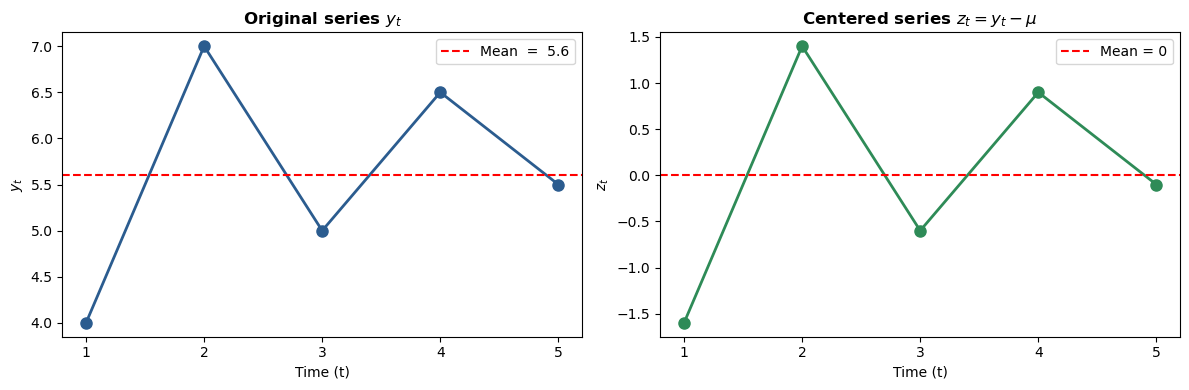

In [2]:
#PLOT THE ORIGINAL AND THE CENTERED SERIES

fig, axes = plt.subplots(1, 2, figsize = (12, 4))

# Original series with its mean
axes[0].plot(time_steps, y, marker = 'o', color = '#2b5c8f', linewidth = 2, markersize = 8)
axes[0].axhline(y = mu, color = 'r', linestyle = '--', label = f'Mean  =  {mu:.1f}')
axes[0].set_title('Original series $y_t$', fontweight = 'bold')
axes[0].set_xlabel('Time (t)')
axes[0].set_ylabel('$y_t$')
axes[0].set_xticks(time_steps)
axes[0].legend()

# Centered series (fluctuates around zero)
axes[1].plot(time_steps, z, marker = 'o', color = '#2e8b57', linewidth = 2, markersize = 8)
axes[1].axhline(y = 0, color = 'r', linestyle = '--', label = 'Mean = 0')
axes[1].set_title('Centered series $z_t = y_t - \\mu$', fontweight = 'bold')
axes[1].set_xlabel('Time (t)')
axes[1].set_ylabel('$z_t$')
axes[1].set_xticks(time_steps)
axes[1].legend()

plt.tight_layout()
plt.show()


In [3]:
# ESTIMATE phi AND theta BY MINIMIZING SSE

from scipy.optimize import least_squares

def residuals(params):
    """Recursive errors eps_t = z_t - phi*z_{t-1} - theta*eps_{t-1}, with z_0 = 0, eps_0 = 0."""
    phi, theta = params
    eps, z_prev, e_prev = [], 0.0, 0.0
    for z_t in z:
        e_prev = z_t - phi * z_prev - theta * e_prev
        eps.append(e_prev)
        z_prev = z_t
    return np.array(eps)

# SSE may have several local minima, so we start from several points
# and keep the best fit; bounds keep the model stationary and invertible
starts = [(a, b) for a in (-0.5, 0, 0.5) for b in (-0.5, 0, 0.5)]
fits = [least_squares(residuals, x0, bounds=([-0.999] * 2, [0.999] * 2)) for x0 in starts]
best = min(fits, key=lambda r: r.cost)

phi_hat, theta_hat = best.x
print(f"phi   = {phi_hat:.4f}")        # -0.0514
print(f"theta = {theta_hat:.4f}")      # -0.8694
print(f"SSE   = {2 * best.cost:.4f}")  # 3.1062


phi   = -0.0514
theta = -0.8694
SSE   = 3.1062


In [4]:
# FORECAST FOR t = 6 (add the mean back)

forecast_value = mu + phi_hat * z[-1] + theta_hat * residuals(best.x)[-1]
print(f"Forecast for t = 6: {forecast_value:.3f}")   # 5.384

Forecast for t = 6: 5.384
